 DS5110 Homework 2: Tidy, Reshape, Join

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

revenue_raw = pd.read_csv("data/raw/company_quarterly_revenue_raw.csv")
orders = pd.read_csv("data/raw/orders.csv")
shipments = pd.read_csv("data/raw/shipments.csv")

Step 0: Descriptive analysis

In [2]:
print("revenue:", revenue_raw.shape)
revenue_raw.head()

revenue: (5, 13)


,company,2023-Q1,2023-Q2,2023-Q3,2023-Q4,2024-Q1,2024-Q2,2024-Q3,2024-Q4,2025-Q1,2025-Q2,2025-Q3,2025-Q4
0,Acme,13.5,14.1,15.9,16.8,15.6,16.7,18.4,17.1,18.6,19.9,20.5,20.3
1,Globex,10.3,8.7,9.4,10.7,13.5,12.0,11.6,11.6,14.0,13.8,15.9,14.0
2,Initech,16.9,15.7,16.7,16.8,17.1,17.9,18.1,18.4,18.6,17.9,20.2,22.3
3,Soylent,10.8,12.9,14.9,15.4,15.5,19.4,20.1,22.1,23.0,22.9,22.0,23.6
4,Umbrella,8.1,6.1,7.7,8.7,9.6,8.7,11.7,10.4,9.8,11.8,12.4,14.3


In [3]:
print("orders:", orders.shape)
orders.head()

orders: (20, 5)


,order_id,customer_id,amount,company,quarter
0,O1000,C106,26,Umbrella,2024-Q4
1,O1001,C105,48,Umbrella,2023-Q3
2,O1002,C103,155,Globex,2025-Q2
3,O1003,C100,38,Acme,2023-Q4
4,O1004,C103,136,Globex,2023-Q3


In [4]:
print("shipments:", shipments.shape)
shipments.head()

shipments: (35, 2)


,order_id,tracking
0,O1000,O1000-1
1,O1001,O1001-1
2,O1001,O1001-2
3,O1002,O1002-1
4,O1003,O1003-1


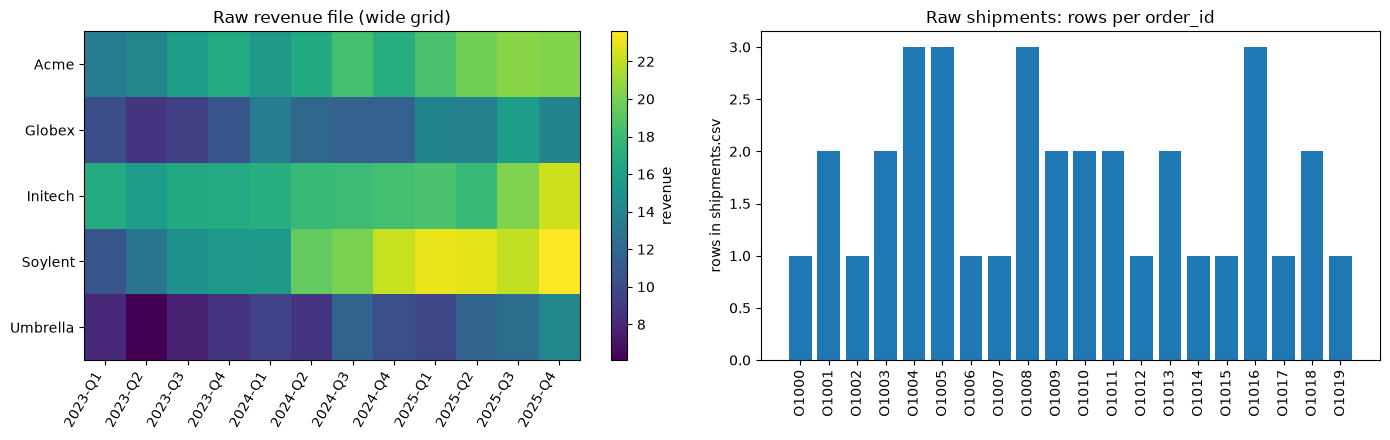

In [5]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.5))

grid = revenue_raw.set_index("company")
im = ax1.imshow(grid.values, aspect="auto")
ax1.set_xticks(range(grid.shape[1]), grid.columns, rotation=60, ha="right")
ax1.set_yticks(range(grid.shape[0]), grid.index)
ax1.set_title("Raw revenue file (wide grid)")
fig.colorbar(im, ax=ax1, label="revenue")

counts = shipments["order_id"].value_counts().sort_index()
ax2.bar(counts.index, counts.values)
ax2.tick_params(axis="x", rotation=90)
ax2.set_ylabel("rows in shipments.csv")
ax2.set_title("Raw shipments: rows per order_id")

plt.tight_layout()
plt.show()